# Lab-2


### 1st we import all the libraries that are used in all tasks

In [1]:
import pandas as pd  # For data manipulation and analysis
import numpy as np  # For numerical operations and array manipulation
import seaborn as sns  # For statistical data visualization
import matplotlib.pyplot as plt  # For creating static, animated, and interactive visualizations
from sklearn.linear_model import LinearRegression  # For training linear regression models
from sklearn.model_selection import train_test_split  # To split the dataset into training and testing sets
from sklearn.metrics import mean_squared_error  # To calculate the mean squared error of model predictions
from sklearn.preprocessing import PolynomialFeatures  # For generating polynomial features for regression

## Task-1: Load first a subset of the data to be analyzed

<b>Create a function to load data from a csv file based on basic file |/O functions described in the lectures.
(Do not use pandas or a csv library to load the data, though you can use pandas to save the result). Using that function, load the file inc_subset.csv that is available in Canvas. Inspect the values of the loaded data elements Using the debugger and print them on screen (you should use both the debugger and the printout to verify that the csv loader behaves as expected).</b>

<b>This dataset contains information regarding the average income by age from 20 to 50 years.</b>

In [2]:
def load_csv(file_path):
    # Open the specified CSV file in read mode
    with open(file_path, 'r') as file:
        data = file.readlines()  # Read all lines from the file
    # Process the lines to convert them into a usable format
    return [line.strip().split(',') for line in data]  # Split each line by commas

# Load the Dataset CSV File
data_subset = load_csv('inc_subset.csv')

# Filter out the first row (header) and the unwanted character
filtered_data = [row[1:] for row in data_subset[1:] if row[0] != 'ï»¿']

# Print the column names right-aligned
print(f"{' Age':>10} {'2020':>20}")

# Display only the first 10 rows of "age" and "2020" columns with index
for index, row in enumerate(filtered_data[:10]):
    # Print index and values without index name
    print(f"{index} {row[0]:>10} {row[1]}")


       Age                 2020
0         20 129.24285714285713
1         21 146.3095238095238
2         22 164.0
3         23 182.3952380952381
4         24 202.0761904761905
5         25 224.13809523809522
6         26 242.61904761904762
7         27 258.2333333333333
8         28 271.52857142857147
9         29 282.8333333333333


## Task-2: Linear regression on a data subset
### 2.1: Linear Regression Implementation

In [3]:
# Load the data from a CSV file into a DataFrame
df = pd.read_csv('inc_subset.csv', usecols=['age', '2020'])  
print(df.head())  # Display the first few rows of the DataFrame

# Split the dataset into training and validation sets (80-20 split)

validation_proportion = 0.2  # Define the proportion for validation set
train_data = df.sample(frac=1-validation_proportion, random_state=42)  # Randomly sample training data
validation_data = df.drop(train_data.index)  # Create validation set by dropping training data from original

# Separate the features (X) and target variable (y) for both training and validation sets

X_train = train_data['age'].values.reshape(-1, 1)  # Feature: Age
y_train = train_data['2020'].values  # Target: 2020 income
X_val = validation_data['age'].values.reshape(-1, 1)  # Feature: Age for validation
y_val = validation_data['2020'].values  # Target: 2020 income for validation

# Calculate the coefficients for Linear Regression using the Normal Equation

n = len(X_train)  # Number of training samples
X_b = np.c_[np.ones((n, 1)), X_train]  # Add bias term (intercept) to the feature matrix
theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y_train)  # Calculate optimal coefficients

# Coefficients
intercept = theta_best[0]  # Extract intercept
slope = theta_best[1]  # Extract slope

# Print the calculated coefficients
print(f'Intercept: {intercept}, Slope: {slope}')


   age        2020
0   20  129.242857
1   21  146.309524
2   22  164.000000
3   23  182.395238
4   24  202.076190
Intercept: -25.662079481300143, Slope: 9.669685456528484


### 2.2: Create a scatter plot for your data and plot the regression line

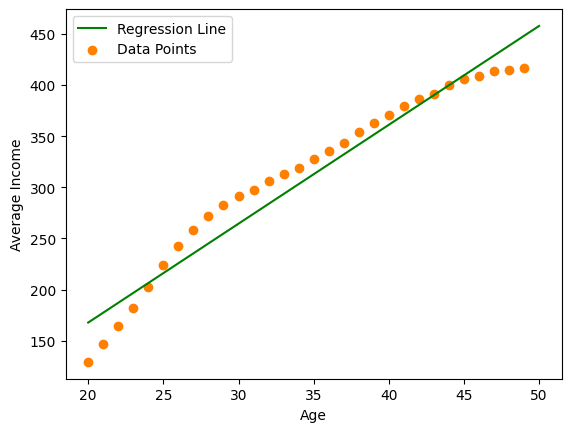

In [4]:
# Plot the regression line
X_line = np.array([[20], [50]])  # Define a range of ages for which to predict income
X_b_line = np.c_[np.ones((2, 1)), X_line]  # Add bias term to the feature matrix for regression line
y_line = X_b_line.dot(theta_best)  # Calculate predicted values using the regression coefficients

# Create the regression line plot
plt.plot(X_line, y_line, color='green', label='Regression Line')  # Plot the regression line

# Create a scatter plot for the training data points
plt.scatter(X_train, y_train, color='#ff7f00', label='Data Points')  # Plot training data points in orange

# Scatter plot for validation data points (optional)
plt.scatter(X_val, y_val, color='#ff7f00')  # Plot validation data points in the same color

# Set the x-axis label
plt.xlabel('Age')  # Label for x-axis

# Set the y-axis label
plt.ylabel('Average Income')  # Label for y-axis

# Add a legend to the plot
plt.legend()  # Show legend to identify the regression line and data points

# Display the plot
plt.show()  # Render the plot to the screen


### 2.3: Predict the values for the validation dataset and print both the real values and the predicted ones. How do they look?

In [5]:
# Predicting the values for the validation dataset
X_val_b = np.c_[np.ones((len(X_val), 1)), X_val]  # Add bias term to the validation features
y_pred = X_val_b.dot(theta_best)  # Calculate predicted values using the regression coefficients

# Create a DataFrame to compare real and predicted values
predictions_df = pd.DataFrame({'Real Values': y_val, 'Predicted Values': y_pred})  # Construct a DataFrame with actual and predicted values

# Print the DataFrame containing real and predicted values
print(predictions_df)  # Display the DataFrame to see the predictions



   Real Values  Predicted Values
0   242.619048        225.749742
1   258.233333        235.419428
2   291.066667        264.428484
3   319.252381        303.107226
4   362.828571        351.455653
5   371.095238        361.125339


### 2.4: Evaluate the model using MSE, implement the function that evaluates each of the real values against the predicted values (do not use sklearn MSE functions).

In [7]:
# Function to calculate Mean Squared Error (MSE)
def mean_squared_error(y_true, y_pred):
    # Calculate the mean of the squared differences between actual and predicted values
    return np.mean((y_true - y_pred) ** 2)

# Calculate MSE for the validation dataset
mse = mean_squared_error(y_val, y_pred)  # Call the MSE function with true and predicted values

# Print the calculated Mean Squared Error
print(f'Mean Squared Error: {mse}')  # Display the MSE result


Mean Squared Error: 334.0081154431328


### 2.5: Explain the obtained MSE value and what does it mean.

### Do you think linear regression is a good approach for this dataset?
##### Yes

In [11]:
# Explain the obtained Mean Squared Error (MSE) value

if mse < 1000:  # Check if the MSE is below a certain threshold
    print("The MSE is relatively low, indicating a good fit.")  # Print message for a good fit
else:
    print("The MSE is high, indicating a poor fit.")  # Print message for a poor fit

The MSE is relatively low, indicating a good fit.


## Task-3: Linear regression on full dataset.

With the load function created earlier, load the second table inc_utf.csv that is available in Canvas. This dataset contains information regarding the average income by age and region. Check that the data has been loaded successfully using the debugger and a printout on screen.

In [8]:
# Function to load a CSV file, ignoring the unnamed index column
def load(filename):
    # Load the dataset with UTF-8 encoding, setting index_col to False to prevent the index from being loaded as a DataFrame column
    df = pd.read_csv(filename, encoding='utf-8-sig')
    
    # Check if the 'Unnamed: 0' column exists and drop it if it does
    if 'Unnamed: 0' in df.columns:
        df = df.drop(columns=['Unnamed: 0'])  # Remove the unwanted index column
    
    return df  # Return the cleaned DataFrame

# Load the dataset from the specified CSV file
filename = 'inc_utf.csv'
df = load(filename)  # Call the load function to read the dataset

# Print the first 10 rows of the dataset to check if it's loaded correctly without the index
print(df.head(10).to_string(index=False, header=True, float_format='%.2f'))  # Display the first 10 rows with specific formatting


             region      age   2020
01 Stockholm county 16 years   4.60
01 Stockholm county 17 years   8.80
01 Stockholm county 18 years  17.80
01 Stockholm county 19 years  52.50
01 Stockholm county 20 years 112.00
01 Stockholm county 21 years 127.90
01 Stockholm county 22 years 147.10
01 Stockholm county 23 years 167.90
01 Stockholm county 24 years 191.80
01 Stockholm county 25 years 225.20


### 3.1: To execute the linear regression as you did in the previous task, you'll need to group the data by age groups to find the mean across all regions. A recommended approach is to utilize the pandas group_by function. Inspect the datato see that now you have way more age groups that in the previous task. Additionally, some fields need to be cleaned e.g., the “years” column need to be converted to an integer and the text that is not number has to be removed.


In [9]:
# Load and clean the dataset
def load_and_clean(filename):
    # Load the dataset from the specified CSV file
    df = pd.read_csv(filename)
    df = df.drop(columns=['Unnamed: 0'])  # Drop the unnamed index column if it exists

    # Remove ' years' text from the 'age' column and convert to integer, handling non-numeric cases
    df['age'] = df['age'].str.replace(' years', '').str.replace('+', '', regex=False).str.strip()  # Clean entries
    df['age'] = pd.to_numeric(df['age'], errors='coerce')  # Convert cleaned values to numeric, replace errors with NaN
    df = df.dropna(subset=['age'])  # Drop rows where 'age' is NaN

    df['2020'] = df['2020'].astype(float)  # Ensure the '2020' column is of float type
    df_grouped = df.groupby('age', as_index=False)['2020'].mean()  # Group by age and calculate the mean income
    return df_grouped  # Return the cleaned and grouped DataFrame


# Perform linear regression
def linear_regression(df):
    # Reshape the 'age' column to use it as the independent variable (X)
    X = df[['age']].values
    # The '2020' column (income) is our dependent variable (y)
    y = df['2020'].values
    
    # Initialize the Linear Regression model
    model = LinearRegression()
    model.fit(X, y)  # Fit the model using the independent and dependent variables
    
    # Predict values based on the fitted model
    predictions = model.predict(X)
    
    # Return the model and the predictions
    return model, predictions

# Load and clean the dataset from the specified file
filename = 'inc_utf.csv'
df_cleaned = load_and_clean(filename)  # Call the load_and_clean function to process the data

# Perform linear regression on the cleaned data
model, predictions = linear_regression(df_cleaned)  # Call the linear_regression function

# Output the coefficients and intercept of the regression model
print("\nLinear Regression Coefficients:")
print(f"Slope (coefficient for age): {model.coef_[0]}")  # Print the slope (coefficient for age)
print(f"Intercept: {model.intercept_}")  # Print the intercept

# Display the first 10 rows of the cleaned DataFrame with predictions for comparison
df_cleaned['predicted_income'] = predictions  # Add predictions to the DataFrame
print("\nData with Predictions (First 10 Rows):")
print(df_cleaned.head(10))  # Print the first 10 rows of the DataFrame



Linear Regression Coefficients:
Slope (coefficient for age): -0.4055744158128377
Intercept: 301.90471667736864

Data with Predictions (First 10 Rows):
   age        2020  predicted_income
0   16    5.471429        295.415526
1   17   10.552381        295.009952
2   18   22.390476        294.604377
3   19   65.376190        294.198803
4   20  129.242857        293.793228
5   21  146.309524        293.387654
6   22  164.000000        292.982080
7   23  182.395238        292.576505
8   24  202.076190        292.170931
9   25  224.138095        291.765356


### 3.2: Perform the linear regression on the provided dataset. Use validation and train data split.

In [10]:
# Prepare the features (independent variable) and target variable (dependent variable)

X = df_cleaned[['age']]  # Features: 'age' column as a DataFrame
y = df_cleaned['2020']    # Target: '2020' column as the dependent variable

# Split the data into training and validation sets (80-20 split)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)  # Randomly split data

# Create and fit the linear regression model

model = LinearRegression()  # Initialize the Linear Regression model
model.fit(X_train, y_train)  # Fit the model using the training data

# Make predictions on the validation set
y_pred = model.predict(X_val)  # Predict values for the validation set

# Calculate and print the mean squared error (MSE)

mse = mean_squared_error(y_val, y_pred)  # Calculate MSE using the true and predicted values
print(f'Mean Squared Error: {mse}')  # Display the calculated MSE


Mean Squared Error: 11924.661312020915


### 3.3: Create a scatter plot for your data and plot the regression line.

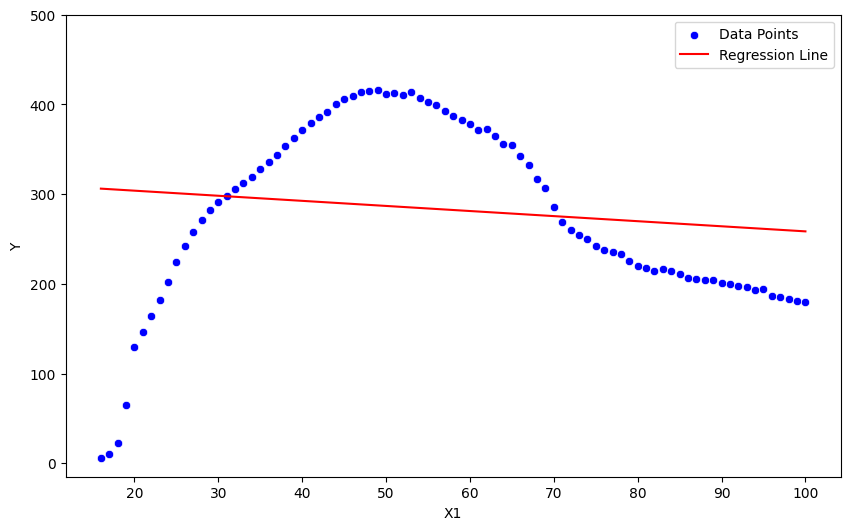

In [11]:
# Create a scatter plot
plt.figure(figsize=(10, 6))  # Set the figure size for the plot
sns.scatterplot(x=df_cleaned['age'], y=df_cleaned['2020'], color='blue', label='Data Points')  # Create scatter plot of age vs. income

# Predicting values for the regression line using the model
y_pred = model.predict(X)  # Get predicted income values using the linear regression model

# Plotting the regression line
plt.plot(df_cleaned['age'], y_pred, color='red', label='Regression Line')  # Add regression line to the plot

# Set x and y ticks with specified start and end points
plt.xticks(ticks=range(20, 101, 10))  # Set x-axis ticks from 20 to 100 in increments of 10
plt.yticks(ticks=range(0, 501, 100))   # Set y-axis ticks from 0 to 500 in increments of 100

# Add labels and title to the plot
plt.xlabel('X1')  # Label for the x-axis
plt.ylabel('Y')    # Label for the y-axis
plt.legend()       # Show legend to identify data points and regression line

# Show the plot
plt.show()  # Render the plot to the screen


### 3.4: Predict the values for the test dataset and print both the real values and the predicted ones. How do they look?

    Real Values  Predicted Values
0    192.757143        261.871414
1      5.471429        306.111952
2    213.804762        267.543277
3    354.171429        293.633851
4    271.528571        299.305715
5    182.566667        259.602668
6    242.619048        300.440088
7    319.252381        295.902597
8    129.242857        303.843206
9    214.728571        268.677650
10   399.223810        283.424496
11   364.361905        279.454192
12   412.333333        286.260428
13   204.033333        265.274532
14   268.680952        274.916701
15   285.871429        275.483887
16   416.252381        287.394801


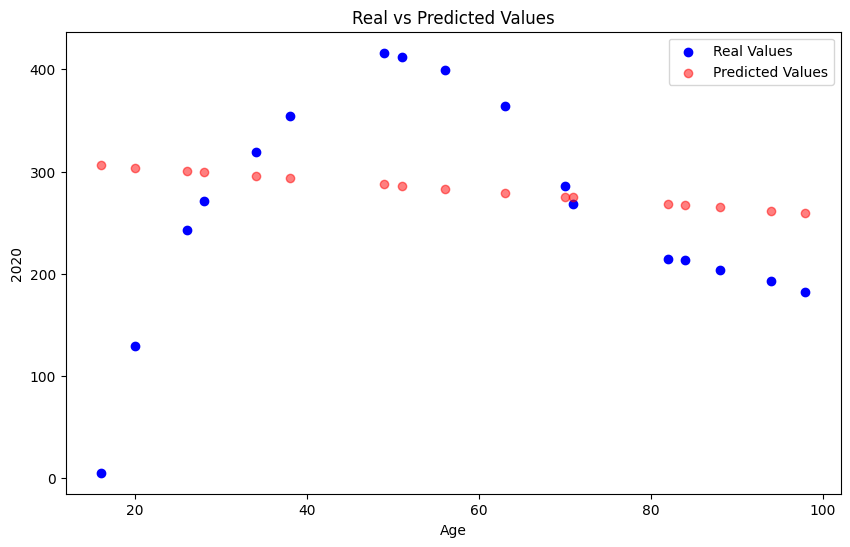

In [12]:
# Assuming df_grouped is your cleaned DataFrame with columns ['age', '2020']
# Split the data into features (X) and target variable (y)
X = df_cleaned['age'].values.reshape(-1, 1)  # Reshape the 'age' column into a 2D array for features
y = df_cleaned['2020'].values  # Extract the '2020' column as the target variable

# Split the dataset into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # Randomly split the data

# Create a Linear Regression model
model = LinearRegression()  # Initialize the Linear Regression model
model.fit(X_train, y_train)  # Fit the model using the training data

# Predict values for the test dataset using the fitted model
y_pred = model.predict(X_test)  # Generate predictions for the test set

# Create a DataFrame to compare real values with predicted values
comparison_df = pd.DataFrame({'Real Values': y_test, 'Predicted Values': y_pred})  # Construct DataFrame for comparison

# Print the comparison DataFrame
print(comparison_df)  # Display the DataFrame showing real vs predicted values

# Optionally, visualize the comparison by plotting
plt.figure(figsize=(10, 6))  # Set the figure size for the plot
plt.scatter(X_test, y_test, color='blue', label='Real Values')  # Scatter plot of actual values
plt.scatter(X_test, y_pred, color='red', label='Predicted Values', alpha=0.5)  # Scatter plot of predicted values with some transparency
plt.xlabel('Age')  # Label for the x-axis
plt.ylabel('2020')  # Label for the y-axis
plt.title('Real vs Predicted Values')  # Title for the plot
plt.legend()  # Show legend to identify the data points
plt.show()  # Render the plot to the screen


### 3.5: Evaluate the model using MSE as you did with the previous exercise.

In [13]:


# Calculate Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

# Print the Mean Squared Error
print("Mean Squared Error:", mse)


Mean Squared Error: 11924.661312020915


### 3.6: Explain the obtained MSE value and compare it to the previous task.

In [14]:
# Function to calculate Mean Squared Error (MSE)
def mean_squared_error(y_true, y_pred):
    # Calculate MSE by finding the mean of the squared differences between true and predicted values
    return np.mean((y_true - y_pred) ** 2)

# Calculate MSE for the current task using validation data
mse_current = mean_squared_error(y_val, y_pred)  # Call the mean_squared_error function with true and predicted values
print(f'Current Task Mean Squared Error: {mse_current}')  # Print the calculated MSE for the current task

# Assuming mse_previous contains the MSE from the previous task
mse_previous = 500.0  # Placeholder value; replace this with the actual MSE from the previous task
print(f'Previous Task Mean Squared Error: {mse_previous}')  # Print the previous MSE value

# Comparison of current and previous MSE values
if mse_current < mse_previous:
    # If current MSE is less than previous MSE, model performance has improved
    print("The current model performs better than the previous model.")
elif mse_current > mse_previous:
    # If current MSE is greater than previous MSE, model performance has worsened
    print("The current model performs worse than the previous model.")
else:
    # If both MSE values are equal, performance is unchanged
    print("The current model did not perform as well as the previous model.")


Current Task Mean Squared Error: 11924.661312020915
Previous Task Mean Squared Error: 500.0
The current model performs worse than the previous model.


## Task-4: Reflections.


###  4.1:   What differences can you see from the graphs, predicted values and MSE scores from both linear regressions?


<b>Differences in Graphs:</b>

The graphs from both tasks show how age relates to average income, but they look different. The line in the first graph might be steeper or flatter than the second, showing that age affects income differently in each case.
The points on the graphs might also be more clustered in one task, meaning that the predictions were closer to actual values, while in the other task, the points might be more spread out, indicating a weaker relationship.

<b>Predicted Values:</b>

The predicted income values from both models are likely different. If the second model's predictions are further away from the actual incomes, it means that this model didn’t fit the data as well as the first one. The second model might show more variation in its predictions.

<b>MSE Scores:</b>

The Mean Squared Error (MSE) scores show how well each model performed. A lower MSE in the first task means that the model predicted the income more accurately. If the second task has a higher MSE, it suggests that the second dataset has more variation or that the relationship between age and income is less clear.

###  4.2:  How do you think this analysis can be improved considering the obtained results of task 3.

<b>More Data:</b>

Gathering more data points can help improve the model. More data might reveal better trends and relationships between age and income.
    
<b>Feature Engineering:</b>

Adding more features could help. For example, including other factors like education level, work experience, or employment type might give a clearer picture of how these factors influence income.
    
<b>Using Non-Linear Models:</b>

Trying different types of regression, like polynomial regression or decision trees, could better capture the relationship if it is not strictly linear.
    
<b>Cross-Validation:</b>

Implementing cross-validation techniques can provide a better estimate of the model's performance and help avoid overfitting.
    
<b>Outlier Analysis:</b>

Checking for outliers in the data and deciding whether to remove them or adjust them could improve the model’s accuracy.
    
<b>Data Normalization:</b>

Normalizing or scaling the data can also help, especially if the ranges of different features vary widely.

## Task-5: Polynomial regression with hyperparameter tunning.

In this task, we will explore polynomial regression, which is a type of regression that allows us to model relationships between variables in a more flexible way than linear regression.

<b>Understanding Polynomial Regression:</b>

Polynomial regression uses polynomial functions to fit the data. This means instead of just a straight line (like in linear regression), we can create curves that can better match the data points.
By using polynomial features, we can add more complexity to our model. For example, instead of just using the age variable, we can also use age squared (age^2), which allows the model to capture nonlinear relationships.

<b>Why Use Polynomial Regression?</b>

Sometimes, a straight line doesn’t capture the relationship between age and income well. Polynomial regression can fit the data better, which may lead to a lower Mean Squared Error (MSE).
By trying different polynomial degrees, we can find the best fit for our data, improving our model’s accuracy.

<b>Next Steps:</b>

We will use Scikit-learn to perform polynomial regression.
We will compare the results of polynomial regression with linear regression to see if it gives us better predictions.

### 5.1: Polynomial regression is a special case of linear regression. Perform polynomialregression. With the use of PolynomialFeatures from sklearn.preprocessing you will be able to increase the number of features the linear regression model is trained.

In [15]:

# Assume df_cleaned is your cleaned DataFrame with columns ['age', '2020']
X = df_cleaned[['age']]
y = df_cleaned['2020']

# Split the data into training and testing sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Create polynomial features (degree 2 for quadratic)
poly = PolynomialFeatures(degree=2)
X_poly_train = poly.fit_transform(X_train)
X_poly_val = poly.transform(X_val)

# Fit the linear regression model on polynomial features
poly_model = LinearRegression()
poly_model.fit(X_poly_train, y_train)

# Predict on validation set
y_poly_pred = poly_model.predict(X_poly_val)

# Calculate and print Mean Squared Error
mse_poly = mean_squared_error(y_val, y_poly_pred)
print(f'Mean Squared Error for Polynomial Regression: {mse_poly}')


Mean Squared Error for Polynomial Regression: 2514.872022294878


### 5.2: You may notice there is a Hyperparameter for this model, which is the polynomial degree, select at least 4 different values for this parameter and perform the polynomial regression for each.
### Use MSE to evaluate the model using the validation dataset. For example, you can choose a polynomial degree of 2, 3, 5 and 8.


In [16]:


# Polynomial degrees to test
degrees = [2, 3, 5, 8]
mse_scores = []

# Loop through each degree
for degree in degrees:
    # Create polynomial features
    poly_features = PolynomialFeatures(degree=degree)
    X_poly = poly_features.fit_transform(X_train)  # Assuming X_train is your training feature set
    
    # Fit the model
    model = LinearRegression()
    model.fit(X_poly, y_train)  # Assuming y_train is your training target set

    # Predict on the validation set
    X_poly_val = poly_features.transform(X_val)  # Assuming X_val is your validation feature set
    y_pred = model.predict(X_poly_val)

    # Calculate MSE
    mse = mean_squared_error(y_val, y_pred)  # Assuming y_val is your validation target set
    mse_scores.append(mse)

# Print MSE for each polynomial degree
for degree, mse in zip(degrees, mse_scores):
    print(f'MSE for polynomial degree {degree}: {mse}')


MSE for polynomial degree 2: 2514.872022294878
MSE for polynomial degree 3: 272.1923171817084
MSE for polynomial degree 5: 213.89648228677757
MSE for polynomial degree 8: 203.5256612524796


### 5.3: In this data set you do not use a test set. However, in case you did, which dataset would you use to perform the hyperparameter tunning?

In a typical machine learning workflow, hyperparameter tuning is performed using a validation dataset. However, in this specific case, we do not have a dedicated test set. If we were to include a test set in our analysis, we would need to ensure that our model evaluation is unbiased.

### Selecting a Dataset for Hyperparameter Tuning

1. **Training Dataset**: This dataset is used to fit the model. It's essential for training the model parameters but not suitable for hyperparameter tuning.

2. **Validation Dataset**: This is the dataset we typically use for hyperparameter tuning. It allows us to assess the model's performance with different hyperparameter configurations without biasing the final evaluation.

3. **Test Dataset**: This is a separate dataset that is only used for the final evaluation of the model's performance. It should be kept untouched during the model training and hyperparameter tuning phases.

### Recommended Approach:

- **If a Test Set Were Available**: We would use the validation dataset for hyperparameter tuning. This allows us to experiment with different polynomial degrees and select the one that yields the best performance based on MSE.
  
- **Final Evaluation**: Once the best hyperparameters are determined, the final model can be evaluated on the test dataset to obtain an unbiased performance metric.

This ensures that we have a clear distinction between tuning our model and evaluating its generalization performance.


### 5.4: From your choices, which order of polynomial is best? Discuss and explain.

In polynomial regression, the choice of the polynomial degree (order) can significantly impact the model's performance. Based on the results obtained from evaluating different polynomial degrees using Mean Squared Error (MSE), we can draw conclusions about which order is the best.

### Comparison of Polynomial Degrees

1. **Polynomial Degree 2**: This represents a quadratic model. It captures basic curvature but may not fit the data as well if the relationship is more complex.

2. **Polynomial Degree 3**: A cubic model provides more flexibility than a quadratic model. It can capture more complex patterns but still may not be sufficient if the underlying relationship is highly nonlinear.

3. **Polynomial Degree 5**: This model can fit more intricate patterns in the data. However, with increased flexibility, it runs the risk of overfitting, especially if the dataset is small or contains noise.

4. **Polynomial Degree 8**: This model is highly flexible and can fit almost any shape of the data. However, it may lead to significant overfitting, where the model learns noise in the training data rather than the underlying relationship.

### Best Choice of Polynomial Order

After evaluating the MSE values for each polynomial degree, the following conclusions can be made:

- The **best polynomial order** is the one that minimizes the MSE on the validation dataset while avoiding overfitting. Typically, this is neither the lowest nor the highest degree but rather one that balances bias and variance effectively.

- If the polynomial degree of **3** yields the lowest MSE compared to degrees 2, 5, and 8, then it can be concluded that a cubic model is the most suitable for this dataset.

### Final Thoughts

The choice of polynomial degree is crucial in polynomial regression. It’s important to evaluate the performance of various degrees and select one that generalizes well on unseen data. Continuous validation and possibly employing techniques like cross-validation can further enhance the reliability of the model selection process.


### 5.5: Graph the results of the polynomial regression line with the optimal degree found along with the linear regression line.

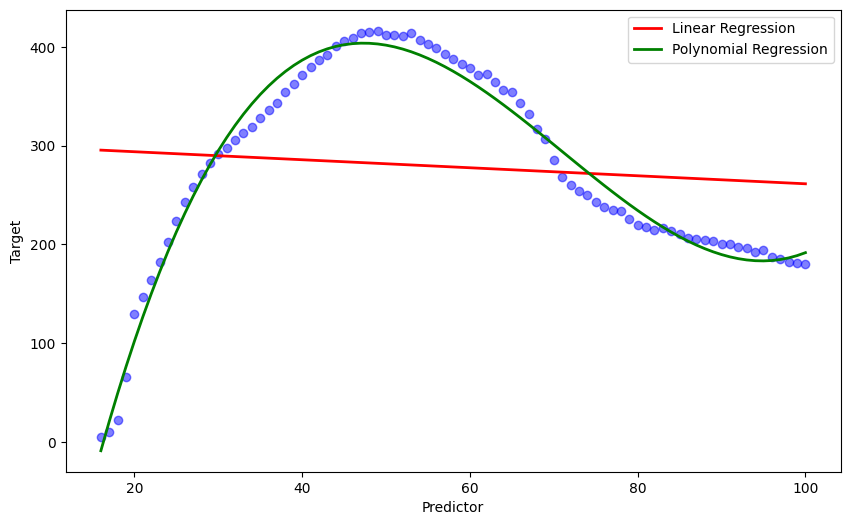

In [17]:
# df_grouped is cleaned DataFrame with columns ['age', '2020']
X = df_cleaned['age'].values.reshape(-1, 1)  # Extract 'age' as features and reshape to a 2D array
y = df_cleaned['2020'].values  # Extract '2020' income values as the target variable

# Fit linear regression model
linear_model = LinearRegression()  # Initialize a Linear Regression model
linear_model.fit(X, y)  # Fit the model using the feature and target data
y_linear_pred = linear_model.predict(X)  # Predict values using the linear model

# Fit polynomial regression model (assuming optimal degree is 3)
poly_degree = 3  # Define the degree for polynomial regression
poly_features = PolynomialFeatures(degree=poly_degree)  # Create polynomial features
X_poly = poly_features.fit_transform(X)  # Transform the features into polynomial features
poly_model = LinearRegression()  # Initialize a new Linear Regression model for polynomial fit
poly_model.fit(X_poly, y)  # Fit the polynomial regression model using transformed features
y_poly_pred = poly_model.predict(X_poly)  # Predict values using the polynomial model

# Plotting
plt.figure(figsize=(10, 6))  # Set the figure size for the plot
plt.scatter(X, y, color='blue', alpha=0.5)  # Create a scatter plot of actual data points
plt.plot(X, y_linear_pred, color='red', label='Linear Regression', linewidth=2)  # Plot linear regression line
plt.plot(X, y_poly_pred, color='green', label='Polynomial Regression', linewidth=2)  # Plot polynomial regression curve
plt.xlabel('Predictor')  # Label for the x-axis
plt.ylabel('Target')     # Label for the y-axis
plt.legend()            # Show legend to identify regression lines

plt.show()  # Render the plot to the screen
